In [1]:
import time

for _, row in extreme_fires.head(2).iterrows():
    payload = {
        "content": "🔴 **[RT - REAL-TIME STREAM] NASA FIRMS WILDFIRE ALERT** 🔴",
        "embeds": [{
            "title": "Live Thermal Anomaly Telemetry",
            "color": 15158332,
            "fields": [
                {"name": "Status", "value": "🟢 RT Active Stream", "inline": True},
                {"name": "Risk Tier", "value": str(row['risk_tier']), "inline": True},
                {"name": "Brightness (RT)", "value": str(row['brightness']), "inline": True},
                {"name": "Coordinates", "value": f"Lat: {row['latitude']}, Lon: {row['longitude']}", "inline": False},
                {"name": "Processed At", "value": time.strftime('%Y-%m-%d %H:%M:%S UTC'), "inline": False}
            ]
        }]
    }
    requests.post(DISCORD_WEBHOOK_URL, json=payload)

NameError: name 'extreme_fires' is not defined

In [2]:
import pandas as pd
import folium
import requests
import json
import time
from datetime import datetime, timezone
import openpyxl  # Required for Excel export (.xlsx)

# --- STEP 1: FETCH LIVE TELEMETRY FROM NASA FIRMS ---
MAP_KEY = "11be2b95414f1e231600092cc3ff7148"
source = "VIIRS_NOAA20_NRT"
area_coords = "world"
day_range = 1
api_url = f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/{MAP_KEY}/{source}/{area_coords}/{day_range}"

print("Step 1: Fetching live telemetry from NASA FIRMS...")
live_df = pd.read_csv(api_url)
print(f"-> Fetched {len(live_df)} live wildfire/thermal records.")

# --- STEP 2: DEFINING PYDANTIC VALIDATION MODEL & RISK SCORING ---
from pydantic import BaseModel, Field
from typing import Optional

class WildfireRecord(BaseModel):
    latitude: float = Field(..., ge=-90, le=90)
    longitude: float = Field(..., ge=-180, le=180)
    brightness: float
    acq_date: str
    risk_tier: Optional[str] = "Moderate"

def assign_risk_tier(bright):
    if bright > 350:
        return "Extreme"
    elif bright > 325:
        return "High"
    elif bright > 300:
        return "Moderate"
    else:
        return "Low"

print("Step 2: Running Pydantic validation and risk scoring...")
validated_rows = []

for _, row in live_df.head(200).iterrows():
    try:
        lat = float(row['latitude'])
        lon = float(row['longitude'])
        bright = float(row['bright_ti4'])
        date_str = str(row['acq_date'])

        record = WildfireRecord(
            latitude=lat,
            longitude=lon,
            brightness=bright,
            acq_date=date_str
        )

        data_dict = record.model_dump()
        data_dict['risk_tier'] = assign_risk_tier(bright)
        validated_rows.append(data_dict)
    except Exception as e:
        continue

validated_df = pd.DataFrame(validated_rows)
print(f"-> Successfully validated {len(validated_df)} records.")

if len(validated_df) > 0:
    # --- STEP 3: SAVE INTO SQLITE DATABASE ---
    print("Step 3: Storing validated records into sqlite database...")
    import sqlite3
    conn = sqlite3.connect("wildfire_pipeline.db")
    validated_df.to_sql("wildfire_events", conn, if_exists="replace", index=False)
    conn.close()
    print("-> Saved successfully to 'wildfire_pipeline.db'.")

    # --- STEP 4: GENERATE ESRI SATELLITE FOLIUM MAP ---
    print("Step 4: Generating live geospatial esri satellite map...")
    map_center = [validated_df['latitude'].mean(), validated_df['longitude'].mean()]
    live_map = folium.Map(location=map_center, zoom_start=3, tiles='Esri.WorldImagery')

    for _, row in validated_df.iterrows():
        tier = row['risk_tier']
        color = "red" if tier == "Extreme" else "orange" if tier == "High" else "yellow" if tier == "Moderate" else "green"

        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=6,
            popup=f"Risk: {tier}<br>Brightness: {row['brightness']}<br>Date: {row['acq_date']}",
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.8
        ).add_to(live_map)

    live_map.fit_bounds([
        [validated_df['latitude'].min(), validated_df['longitude'].min()],
        [validated_df['latitude'].max(), validated_df['longitude'].max()]
    ])
    print("-> Live Map generated successfully!")

    # --- STEP 5: AUTOMATED MULTI-FORMAT ANALYTICS & BATCH REPORTING ---
    print("Step 5: Generating analytical JSON, CSV, and Excel export files...")
    total_events = len(validated_df)
    avg_brightness = round(validated_df['brightness'].mean(), 2)
    tier_counts = validated_df['risk_tier'].value_counts().to_dict()

    now_utc = datetime.now(timezone.utc)
    timestamp_str = now_utc.strftime('%Y%m%d_%H%M%S')

    # 1. JSON Summary Report
    json_filename = f"wildfire_report_{timestamp_str}.json"
    report_data = {
        "execution_timestamp_utc": now_utc.strftime('%Y-%m-%d %H:%M:%S'),
        "total_records_processed": total_events,
        "average_brightness_kelvin": avg_brightness,
        "risk_tier_breakdown": tier_counts
    }
    with open(json_filename, "w") as f:
        json.dump(report_data, f, indent=4)
    print(f"-> JSON report saved: '{json_filename}'")

    # 2. CSV Dataset Export
    csv_filename = f"wildfire_dataset_{timestamp_str}.csv"
    validated_df.to_csv(csv_filename, index=False)
    print(f"-> CSV dataset saved: '{csv_filename}'")

    # 3. Excel Spreadsheet Export (.xlsx)
    excel_filename = f"wildfire_dataset_{timestamp_str}.xlsx"
    validated_df.to_excel(excel_filename, index=False, sheet_name="Wildfire Telemetry")
    print(f"-> Excel spreadsheet saved: '{excel_filename}'")

    # --- STEP 6: DISCORD WEBHOOK ALERTS FOR EXTREME EVENTS ---
    DISCORD_WEBHOOK_URL = "https://discord.com/api/webhooks/1559237316734619689/rRGo1yahxxLI0pccKnbr-uPhqxx6Pojhef8Ll2ZQTd2bsk-aTSpiIQvKQ4LEKKY82058"

    extreme_fires = validated_df[validated_df['risk_tier'] == "Extreme"]
    print(f"Step 6: Scanning for Extreme risks... Found {len(extreme_fires)} extreme event(s).")

    for _, row in extreme_fires.head(10).iterrows():
        payload = {
            "content": "🔴 **[RT - REAL-TIME STREAM] NASA FIRMS WILDFIRE ALERT** 🔴",
            "embeds": [{
                "title": "Live Thermal Anomaly Telemetry",
                "color": 15158332,
                "fields": [
                    {"name": "Status", "value": "🟢 RT Active Stream", "inline": True},
                    {"name": "Risk Tier", "value": str(row['risk_tier']), "inline": True},
                    {"name": "Batch Avg Brightness", "value": f"{avg_brightness} K", "inline": True},
                    {"name": "Brightness (Event)", "value": str(row['brightness']), "inline": True},
                    {"name": "Coordinates", "value": f"Lat: {row['latitude']}, Lon: {row['longitude']}", "inline": False},
                    {"name": "Processed At", "value": time.strftime('%Y-%m-%d %H:%M:%S UTC'), "inline": False}
                ]
            }]
        }

        response = requests.post(DISCORD_WEBHOOK_URL, json=payload)
        if response.status_code in [200, 204]:
            print(f" -> Alert successfully sent to Discord! (Lat: {row['latitude']}, Lon: {row['longitude']})")
        else:
            print(f" -> Failed to send alert. Status: {response.status_code} | Reason: {response.text}")

        time.sleep(1)

    print("\n✅ FULL LIVE PIPELINE & ANALYTICS EXECUTION COMPLETE!")
else:
    print("Warning: No records passed validation. Check raw dataframe columns.")

Step 1: Fetching live telemetry from NASA FIRMS...
-> Fetched 11531 live wildfire/thermal records.
Step 2: Running Pydantic validation and risk scoring...
-> Successfully validated 200 records.
Step 3: Storing validated records into sqlite database...
-> Saved successfully to 'wildfire_pipeline.db'.
Step 4: Generating live geospatial esri satellite map...
-> Live Map generated successfully!
Step 5: Generating analytical JSON, CSV, and Excel export files...
-> JSON report saved: 'wildfire_report_20261114_132001.json'
-> CSV dataset saved: 'wildfire_dataset_20261114_132001.csv'
-> Excel spreadsheet saved: 'wildfire_dataset_20261114_132001.xlsx'
Step 6: Scanning for Extreme risks... Found 0 extreme event(s).

✅ FULL LIVE PIPELINE & ANALYTICS EXECUTION COMPLETE!


In [3]:
%%writefile app.py
import streamlit as st
import pandas as pd
import sqlite3
import folium
from streamlit_folium import st_folium
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional seaborn theme
sns.set_theme(style="whitegrid")

st.set_page_config(
    page_title="NASA FIRMS Wildfire Monitoring Dashboard",
    page_icon="🔥",
    layout="wide"
)

st.title("🔥 NASA FIRMS Real-Time Global Wildfire Monitoring Dashboard")
st.markdown("Production-grade data engineering pipeline tracking thermal anomalies, risk tiers, and telemetry.")

# --- LOAD DATA FROM SQLITE DATABASE ---
@st.cache_data
def load_data():
    if not os.path.exists("wildfire_pipeline.db"):
        return pd.DataFrame()
    conn = sqlite3.connect("wildfire_pipeline.db")
    df = pd.read_sql("SELECT * FROM wildfire_events", conn)
    conn.close()
    return df

df = load_data()

if df.empty:
    st.warning("⚠️ No wildfire data found in 'wildfire_pipeline.db'. Please run your master pipeline cell first to populate the database!")
else:
    # --- SIDEBAR FILTERS ---
    st.sidebar.header("Dashboard Controls")
    selected_risk = st.sidebar.selectbox(
        "Filter by Risk Tier",
        ["All", "Extreme", "High", "Moderate", "Low"]
    )

    if selected_risk != "All":
        filtered_df = df[df['risk_tier'] == selected_risk]
    else:
        filtered_df = df

    # --- TOP METRICS ROW ---
    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Records Processed", len(df))
    col2.metric("Average Brightness", f"{round(df['brightness'].mean(), 2)} K")
    col3.metric("Extreme Risk Count", len(df[df['risk_tier'] == 'Extreme']))
    col4.metric("High Risk Count", len(df[df['risk_tier'] == 'High']))

    st.markdown("----")

    # --- MAP & DATA TABLE LAYOUT ---
    map_col, table_col = st.columns([1.2, 1])

    with map_col:
        st.subheader("🌍 Geospatial Satellite Map (Esri Imagery)")
        map_center = [filtered_df['latitude'].mean(), filtered_df['longitude'].mean()] if not filtered_df.empty else [0, 0]
        live_map = folium.Map(location=map_center, zoom_start=3, tiles='esri.worldimagery')

        for _, row in filtered_df.iterrows():
            tier = row['risk_tier']
            color = "red" if tier == "Extreme" else "orange" if tier == "High" else "yellow" if tier == "Moderate" else "green"

            folium.CircleMarker(
                location=[row['latitude'], row['longitude']],
                radius=6,
                popup=f"Risk: {tier}<br>Brightness: {row['brightness']}<br>Date: {row['acq_date']}",
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.8
            ).add_to(live_map)

        st_folium(live_map, width=650, height=450)

    with table_col:
        st.subheader("📊 Filtered Telemetry Records")
        st.dataframe(filtered_df[['latitude', 'longitude', 'brightness', 'risk_tier', 'acq_date']], height=450)

    # --- EXPLORATORY DATA ANALYSIS (EDA) CHARTS SECTION ---
    st.markdown("----")
    st.subheader("📈 Statistical EDA & Visual Reports")
    st.markdown("Academic visualizations analyzing brightness distributions, risk categories, and geospatial correlations.")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- Chart 1: Brightness Temperature Distribution ---
    sns.histplot(df['brightness'], kde=True, ax=axes[0], color='crimson')
    axes[0].set_title("Brightness Temperature Distribution")
    axes[0].set_xlabel("Brightness (Kelvin)")
    axes[0].set_ylabel("Frequency")

    # --- Chart 2: Wildfire Count by Risk Tier ---
    risk_order = ['Extreme', 'High', 'Moderate', 'Low']
    sns.countplot(x='risk_tier', data=df, ax=axes[1], order=[r for r in risk_order if r in df['risk_tier'].unique()], palette='rocket')
    axes[1].set_title("Thermal Anomalies by Risk Tier")
    axes[1].set_xlabel("Risk Tier")
    axes[1].set_ylabel("Record Count")

    # --- Chart 3: Brightness vs. Latitude Correlation Scatter Plot ---
    if 'latitude' in df.columns and 'brightness' in df.columns:
        sns.scatterplot(x='latitude', y='brightness', hue='risk_tier', data=df, ax=axes[2], palette='deep')
        axes[2].set_title("Brightness vs. Latitude Correlation")
        axes[2].set_xlabel("Latitude (°)")
        axes[2].set_ylabel("Brightness (Kelvin)")
    else:
        axes[2].text(0.5, 0.5, "Data Unavailable", horizontalalignment='center', verticalalignment='center')
        axes[2].set_title("Correlation Plot Unavailable")

    plt.tight_layout()
    st.pyplot(fig)

    # --- DOWNLOAD SECTION ---
    st.markdown("----")
    st.subheader("📥 Export & Reports")

    col_dl1, col_dl2 = st.columns(2)

    with col_dl1:
        csv_data = df.to_csv(index=False).encode('utf-8')
        st.download_button(
            label="Download Full Dataset as CSV",
            data=csv_data,
            file_name="wildfire_export.csv",
            mime="text/csv"
        )

    with col_dl2:
        report_summary = {
            "total_records": len(df),
            "average_brightness": round(df['brightness'].mean(), 2),
            "risk_breakdown": df['risk_tier'].value_counts().to_dict()
        }
        json_data = json.dumps(report_summary, indent=4)
        st.download_button(
            label="Download Summary Report as JSON",
            data=json_data,
            file_name="wildfire_report.json",
            mime="application/json"
        )

Writing app.py


/tmp/ipykernel_2050/3137272033.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='risk_tier', data=df, ax=axes[1], order=[r for r in risk_order if r in df['risk_tier'].unique()], palette='rocket')


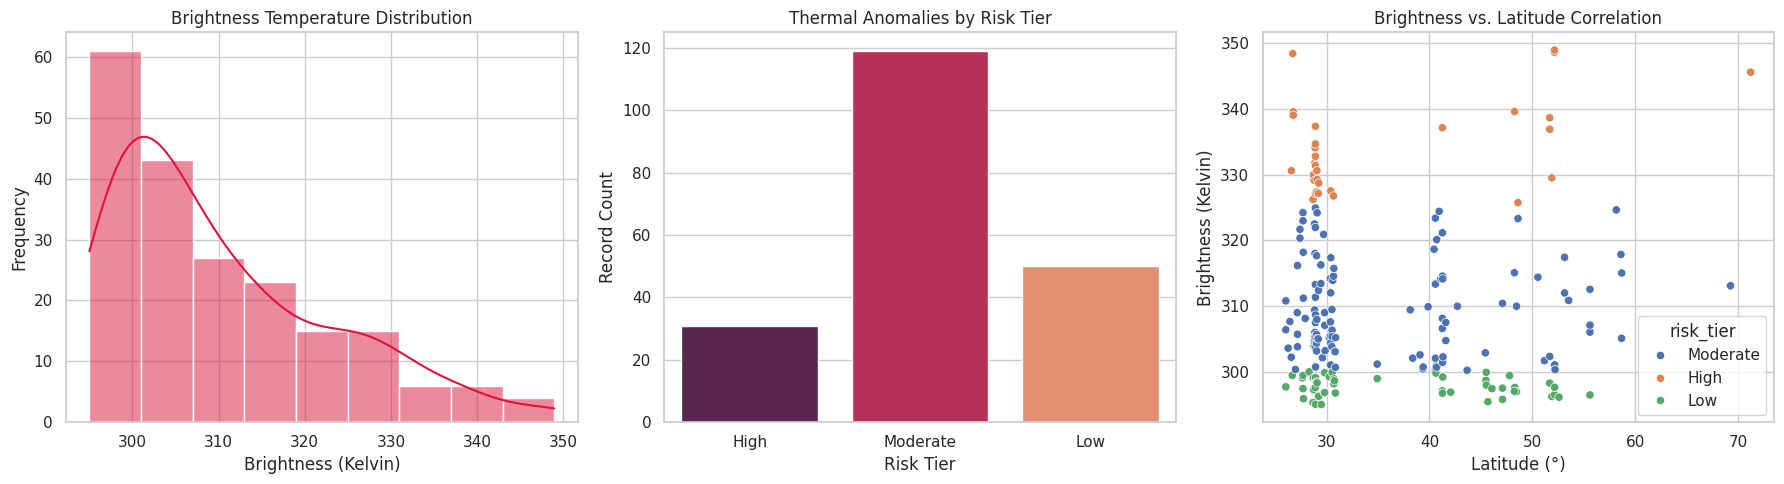


📊 --- Statistical Summary for EDA Report ---
       brightness    latitude   longitude
count  200.000000  200.000000  200.000000
mean   310.333950   36.231820   22.693436
std     12.801642    9.971471   10.058986
min    295.020000   26.031600    5.635830
25%    300.170000   28.909660   16.304552
50%    306.010000   30.399365   21.366340
75%    317.707500   41.586830   30.387880
max    348.950000   71.234180   66.915500


In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional seaborn academic theme
sns.set_theme(style="whitegrid")

# Load data from your SQLite database
conn = sqlite3.connect("wildfire_pipeline.db")
df = pd.read_sql("SELECT * FROM wildfire_events", conn)
conn.close()

if df.empty:
    print("⚠️ No data found in 'wildfire_pipeline.db'. Please run your ingestion pipeline cell first!")
else:
    # Create a multi-panel figure for your EDA report
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- Chart 1: Brightness Temperature Distribution ---
    sns.histplot(df['brightness'], kde=True, ax=axes[0], color='crimson')
    axes[0].set_title("Brightness Temperature Distribution")
    axes[0].set_xlabel("Brightness (Kelvin)")
    axes[0].set_ylabel("Frequency")

    # --- Chart 2: Wildfire Count by Risk Tier ---
    risk_order = ['Extreme', 'High', 'Moderate', 'Low']
    sns.countplot(x='risk_tier', data=df, ax=axes[1], order=[r for r in risk_order if r in df['risk_tier'].unique()], palette='rocket')
    axes[1].set_title("Thermal Anomalies by Risk Tier")
    axes[1].set_xlabel("Risk Tier")
    axes[1].set_ylabel("Record Count")

    # --- Chart 3: Brightness vs. Latitude Correlation Scatter Plot ---
    if 'latitude' in df.columns and 'brightness' in df.columns:
        sns.scatterplot(x='latitude', y='brightness', hue='risk_tier', data=df, ax=axes[2], palette='deep')
        axes[2].set_title("Brightness vs. Latitude Correlation")
        axes[2].set_xlabel("Latitude (°)")
        axes[2].set_ylabel("Brightness (Kelvin)")
    else:
        axes[2].text(0.5, 0.5, "Data Unavailable", horizontalalignment='center', verticalalignment='center')
        axes[2].set_title("Correlation Plot Unavailable")

    plt.tight_layout()
    plt.show()

    # Print safe statistical summary for your report
    print("\n📊 --- Statistical Summary for EDA Report ---")
    avail_cols = [col for col in ['brightness', 'latitude', 'longitude'] if col in df.columns]
    print(df[avail_cols].describe())

In [ ]:
# 1. Install Streamlit and Cloudflared dependencies to be safe
!pip install -q streamlit streamlit-folium openpyxl

# 2. Start Streamlit cleanly using Python module syntax
import time
import subprocess

print("🚀 Starting Streamlit server...")
streamlit_process = subprocess.Popen(["python", "-m", "streamlit", "run", "app.py"])

# 3. Wait 4 seconds for Streamlit to initialize
time.sleep(4)

# 4. Launch Cloudflare tunnel to generate your public web link
print("🌐 Opening Cloudflare public tunnel...")
!./cloudflared tunnel --url http://localhost:8501